# 04C duration adjusted robustness

**Purpose.** Implement the authorized Phase 1 repair with preserved source values. Population: All 1,048,575 rows for matching/counterexamples; fixed regression sample 200,000, seed 2026.

**Hypothesis.** FX and/or gap can have conditional associations even if their observed median penalties are not universally positive.

**Methodology.** OLS for log1p(seconds) and binomial GLM for >900s include FX, gap, participants, route, currency group, log1p(USD) and party. HC1 pointwise intervals; five random/time partitions. Binary >300/>1800 sensitivity uses the same full regression sample. Exact shared strata require >=20/arm; compare adjacent FX within all other strata and gap within route/participants/FX/currency group/amount band/party. Min-arm overlap weights and independent-cell analytic intervals are reused from the verified helper. No unsupported stratum is extrapolated. Currency groups are the top 20 by population frequency plus OTHER; no outcome screening is used.

All duration calculations are seconds; rate differences are percentage points. Amount is USD-normalized. UNLABELED is not verified normal. Source placeholders, outliers and labels are retained. Private output tables can contain competition data and must not be committed or published.


In [1]:
from pathlib import Path
import sys
from IPython.display import display, Markdown, Image
ROOT = Path.cwd().resolve()
if not (ROOT / "data/cleaned/swift_payments_cleaned.csv").exists():
    ROOT = ROOT.parent
assert Path(sys.executable).resolve() == (ROOT / ".venv/Scripts/python.exe").resolve()
sys.path.insert(0, str(ROOT / "src"))
from phase1_analysis import Phase, adjusted_duration
phase = Phase(ROOT, '04C_duration_adjusted_robustness', 'duration/adjusted')


## Code and evidence

The implementation is in `src/phase1_analysis.py`. All displayed values and exports are calculated; group denominators and support restrictions are included in each output table. Models are associational. Fixed sampling avoids repeated fitting on the entire text-heavy dataset; full-population descriptive evidence remains intact.


In [2]:
effects, matching, fx_counterexamples, gap_counterexamples = adjusted_duration(phase)
display(effects)
display(matching)

Duration model log_duration full


Duration model log_duration random_development


Duration model log_duration random_validation


Duration model log_duration chronological_early


Duration model log_duration chronological_late


Duration model IS_SLOW_900 full


... (2 outputs left out)

Duration model IS_SLOW_900 chronological_early


Duration model IS_SLOW_900 chronological_late


,feature,coefficient,ci_low,ci_high,p_value,split,outcome,model_n,effect_unit,exp_coefficient,exp_ci_low,exp_ci_high,exp_interpretation
26,fx,-0.057189,-0.075504,-0.038874,9.349531e-10,full,log_duration,200000,log(1+duration seconds) per unit,0.944415,0.927276,0.961871,Ratio of conditional geometric(duration+1); no...
27,gap,0.003266,-0.028730,0.035262,8.414299e-01,full,log_duration,200000,log(1+duration seconds) per unit,1.003271,0.971679,1.035891,Ratio of conditional geometric(duration+1); no...
26,fx,-0.065124,-0.090978,-0.039269,7.939795e-07,random_development,log_duration,100445,log(1+duration seconds) per unit,0.936952,0.913038,0.961492,Ratio of conditional geometric(duration+1); no...
27,gap,-0.009912,-0.055034,0.035210,6.667911e-01,random_development,log_duration,100445,log(1+duration seconds) per unit,0.990137,0.946453,1.035837,Ratio of conditional geometric(duration+1); no...
26,fx,-0.049554,-0.075499,-0.023609,1.815045e-04,random_validation,log_duration,99555,log(1+duration seconds) per unit,0.951654,0.927281,0.976668,Ratio of conditional geometric(duration+1); no...
27,gap,0.015989,-0.029404,0.061382,4.899695e-01,random_validation,log_duration,99555,log(1+duration seconds) per unit,1.016117,0.971024,1.063305,Ratio of conditional geometric(duration+1); no...
26,fx,-0.061227,-0.086996,-0.035457,3.212194e-06,chronological_early,log_duration,100000,log(1+duration seconds) per unit,0.940610,0.916681,0.965164,Ratio of conditional geometric(duration+1); no...
27,gap,-0.004094,-0.049270,0.041082,8.590138e-01,chronological_early,log_duration,100000,log(1+duration seconds) per unit,0.995914,0.951924,1.041937,Ratio of conditional geometric(duration+1); no...
26,fx,-0.052997,-0.079034,-0.026959,6.625969e-05,chronological_late,log_duration,100000,log(1+duration seconds) per unit,0.948383,0.924008,0.973401,Ratio of conditional geometric(duration+1); no...
27,gap,0.010353,-0.034973,0.055678,6.543917e-01,chronological_late,log_duration,100000,log(1+duration seconds) per unit,1.010406,0.965632,1.057257,Ratio of conditional geometric(duration+1); no...


,population_n,treated_n,baseline_n,outcome,strata,min_cell_per_arm,shared_strata,status,supported_treated_n,supported_baseline_n,...,relative_ci_high,effect_unit,raw_difference_common_support,minimum_stratum_difference,maximum_stratum_difference,contrast,split,difference_pp,ci_low_pp,ci_high_pp
0,1048575,80504,968071,log_duration,route + participants + currency_group + amount...,20,687,ESTIMATED,63700,840184,...,0.005645,log(1+duration seconds),0.177433,-1.130634,1.143680,gap 1 vs 0,full,NaN,NaN,NaN
1,731454,617573,113881,log_duration,route + participants + currency_group + amount...,20,195,ESTIMATED,517400,112024,...,-0.124947,log(1+duration seconds),-0.126813,-2.245221,1.023602,FX 1 vs 0,full,NaN,NaN,NaN
2,829292,211719,617573,log_duration,route + participants + currency_group + amount...,20,308,ESTIMATED,188381,55332,...,0.038122,log(1+duration seconds),0.041010,-1.209489,1.094823,FX 2 vs 1,full,NaN,NaN,NaN
3,281780,70061,211719,log_duration,route + participants + currency_group + amount...,20,216,ESTIMATED,57474,26046,...,0.032937,log(1+duration seconds),0.023366,-0.835210,0.807294,FX 3 vs 2,full,NaN,NaN,NaN
4,93649,23588,70061,log_duration,route + participants + currency_group + amount...,20,118,ESTIMATED,16085,9628,...,0.046448,log(1+duration seconds),0.018409,-0.661001,1.194694,FX 4 vs 3,full,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
125,566,151,415,IS_SLOW_900,route + participants + currency_group + amount...,20,0,NO_COMMON_SUPPORT,0,0,...,NaN,rate fraction; use difference_pp for percentag...,NaN,NaN,NaN,FX 8 vs 7,chronological_late,NaN,NaN,NaN
126,202,51,151,IS_SLOW_900,route + participants + currency_group + amount...,20,0,NO_COMMON_SUPPORT,0,0,...,NaN,rate fraction; use difference_pp for percentag...,NaN,NaN,NaN,FX 9 vs 8,chronological_late,NaN,NaN,NaN
127,65,14,51,IS_SLOW_900,route + participants + currency_group + amount...,20,0,NO_COMMON_SUPPORT,0,0,...,NaN,rate fraction; use difference_pp for percentag...,NaN,NaN,NaN,FX 10 vs 9,chronological_late,NaN,NaN,NaN
128,20,6,14,IS_SLOW_900,route + participants + currency_group + amount...,20,0,NO_COMMON_SUPPORT,0,0,...,NaN,rate fraction; use difference_pp for percentag...,NaN,NaN,NaN,FX 11 vs 10,chronological_late,NaN,NaN,NaN


## Interpretation, limitations and business implications

Interpret only the estimated populations. Log-duration contrasts are not raw median changes; odds ratios are not risk ratios. Rate denominators are group-specific and slow thresholds are exploratory cut-offs, not Swift SLAs. Internal random and chronological checks are not external validation. Related payment families, residual bank/currency composition, coarse amount controls and sparse support limit causal interpretation. BIC outcome-overlap selection changes the estimand.

Use the evidence for source authority, supported segment monitoring and investigation priorities; no savings, fraud accuracy or operational improvement is inferred. An unexplained residual or insufficient common support is a valid result.


{
  "name": "04C_duration_adjusted_robustness",
  "run": "20261115T003904412895Z",
  "source_population": 1048575,
  "source_hashes": {
    "data\\cleaned\\swift_payments_cleaned.csv": "f8b2d946f647e02778d3b232be2f10a91f4adbf1b06c72045c075319a3a9d85c",
    "data\\raw\\swift_payments_raw_export.csv": "ea0eaa18311df2c9332aec336a198307df2996559f7f5abc2840ea0ef2d46d29",
    "data\\raw\\swift_umdac_datathon_2026_fictitious_payment_data.xlsx": "5787b5f9fee3ebcb8ab35462eab75931e70e77dc601c091f334d72dd9e32ea57"
  },
  "files": [
    "outputs\\tables\\duration\\adjusted\\adjusted_model_design.csv",
    "outputs\\tables\\duration\\adjusted\\adjusted_fx_gap_models.csv",
    "outputs\\tables\\duration\\adjusted\\adjusted_fx_gap_effects.csv",
    "outputs\\tables\\duration\\adjusted\\gap_log_duration_matched_strata.csv",
    "outputs\\tables\\duration\\adjusted\\fx_0_log_duration_strata.csv",
    "outputs\\tables\\duration\\adjusted\\fx_1_log_duration_strata.csv",
    "outputs\\tables\\duration\\ad

## Final findings and limitations
Full-sample adjusted effects: [{"feature":"fx","coefficient":-0.0571892414,"ci_low":-0.0755040054,"ci_high":-0.0388744773,"p_value":0.0000000009,"split":"full","outcome":"log_duration","model_n":200000,"effect_unit":"log(1+duration seconds) per unit","exp_coefficient":0.94441533,"exp_ci_low":0.9272760164,"exp_ci_high":0.9618714383,"exp_interpretation":"Ratio of conditional geometric(duration+1); not median"},{"feature":"gap","coefficient":0.0032660428,"ci_low":-0.0287302162,"ci_high":0.0352623017,"p_value":0.8414298759,"split":"full","outcome":"log_duration","model_n":200000,"effect_unit":"log(1+duration seconds) per unit","exp_coefficient":1.0032713821,"exp_ci_low":0.9716785723,"exp_ci_high":1.0358913893,"exp_interpretation":"Ratio of conditional geometric(duration+1); not median"},{"feature":"fx","coefficient":0.0106171125,"ci_low":-0.0107734909,"ci_high":0.0320077158,"p_value":0.3306439033,"split":"full","outcome":"IS_SLOW_900","model_n":200000,"effect_unit":"log odds per unit","exp_coefficient":1.010673674,"exp_ci_low":0.9892843353,"exp_ci_high":1.0325254721,"exp_interpretation":"Odds ratio; not risk ratio"},{"feature":"gap","coefficient":-0.0161338113,"ci_low":-0.0531276527,"ci_high":0.0208600301,"p_value":0.3926715563,"split":"full","outcome":"IS_SLOW_900","model_n":200000,"effect_unit":"log odds per unit","exp_coefficient":0.9839956415,"exp_ci_low":0.948258957,"exp_ci_high":1.0210791213,"exp_interpretation":"Odds ratio; not risk ratio"}]

Supported full matched comparisons: [{"population_n":1048575,"treated_n":80504,"baseline_n":968071,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party + fx","min_cell_per_arm":20,"shared_strata":687,"status":"ESTIMATED","supported_treated_n":63700,"supported_baseline_n":840184,"treated_support_fraction":0.7912650303,"baseline_support_fraction":0.8678950201,"raw_difference":0.2535188528,"adjusted_difference":-0.0101517793,"ci_low":-0.0259331148,"ci_high":0.0056295561,"uncertainty_status":"ESTIMATED","negative_strata":343.0,"positive_strata":344.0,"relative_geometric_duration_plus_one":-0.010100424,"relative_ci_low":-0.0255997396,"relative_ci_high":0.0056454318,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":0.1774330659,"minimum_stratum_difference":-1.1306340661,"maximum_stratum_difference":1.1436804495,"contrast":"gap 1 vs 0","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":731454,"treated_n":617573,"baseline_n":113881,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":195,"status":"ESTIMATED","supported_treated_n":517400,"supported_baseline_n":112024,"treated_support_fraction":0.8377956938,"baseline_support_fraction":0.9836935046,"raw_difference":-0.1314152128,"adjusted_difference":-0.1469984555,"ci_low":-0.1605263594,"ci_high":-0.1334705516,"uncertainty_status":"ESTIMATED","negative_strata":139.0,"positive_strata":56.0,"relative_geometric_duration_plus_one":-0.1367046892,"relative_ci_low":-0.1483046269,"relative_ci_high":-0.1249467625,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":-0.1268125291,"minimum_stratum_difference":-2.2452206414,"maximum_stratum_difference":1.0236021747,"contrast":"FX 1 vs 0","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":829292,"treated_n":211719,"baseline_n":617573,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":308,"status":"ESTIMATED","supported_treated_n":188381,"supported_baseline_n":55332,"treated_support_fraction":0.8897689863,"baseline_support_fraction":0.0895958858,"raw_difference":0.5657961901,"adjusted_difference":0.0192758937,"ci_low":0.0011383977,"ci_high":0.0374133896,"uncertainty_status":"ESTIMATED","negative_strata":141.0,"positive_strata":167.0,"relative_geometric_duration_plus_one":0.0194628732,"relative_ci_low":0.0011390459,"relative_ci_high":0.038122081,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":0.0410100898,"minimum_stratum_difference":-1.2094887749,"maximum_stratum_difference":1.0948227504,"contrast":"FX 2 vs 1","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":281780,"treated_n":70061,"baseline_n":211719,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":216,"status":"ESTIMATED","supported_treated_n":57474,"supported_baseline_n":26046,"treated_support_fraction":0.8203422732,"baseline_support_fraction":0.1230215522,"raw_difference":0.4691513885,"adjusted_difference":0.0057753391,"ci_low":-0.0208555498,"ci_high":0.032406228,"uncertainty_status":"ESTIMATED","negative_strata":110.0,"positive_strata":106.0,"relative_geometric_duration_plus_one":0.0057920485,"relative_ci_low":-0.0206395769,"relative_ci_high":0.0329370281,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":0.0233658294,"minimum_stratum_difference":-0.8352098509,"maximum_stratum_difference":0.8072935939,"contrast":"FX 3 vs 2","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":93649,"treated_n":23588,"baseline_n":70061,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":118,"status":"ESTIMATED","supported_treated_n":16085,"supported_baseline_n":9628,"treated_support_fraction":0.6819145328,"baseline_support_fraction":0.1374231027,"raw_difference":0.3596174926,"adjusted_difference":0.0022791203,"ci_low":-0.0408432366,"ci_high":0.0454014772,"uncertainty_status":"ESTIMATED","negative_strata":57.0,"positive_strata":61.0,"relative_geometric_duration_plus_one":0.0022817194,"relative_ci_low":-0.0400203922,"relative_ci_high":0.0464479005,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":0.0184091588,"minimum_stratum_difference":-0.6610007953,"maximum_stratum_difference":1.1946941885,"contrast":"FX 4 vs 3","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":31386,"treated_n":7798,"baseline_n":23588,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":57,"status":"ESTIMATED","supported_treated_n":4086,"supported_baseline_n":3124,"treated_support_fraction":0.5239805078,"baseline_support_fraction":0.1324402238,"raw_difference":0.335597368,"adjusted_difference":-0.0122202235,"ci_low":-0.0865720287,"ci_high":0.0621315817,"uncertainty_status":"ESTIMATED","negative_strata":27.0,"positive_strata":30.0,"relative_geometric_duration_plus_one":-0.0121458598,"relative_ci_low":-0.0829305089,"relative_ci_high":0.0641023519,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":-0.0003788784,"minimum_stratum_difference":-0.9526521605,"maximum_stratum_difference":0.9224085542,"contrast":"FX 5 vs 4","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":10432,"treated_n":2634,"baseline_n":7798,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":17,"status":"ESTIMATED","supported_treated_n":739,"supported_baseline_n":727,"treated_support_fraction":0.2805618831,"baseline_support_fraction":0.0932290331,"raw_difference":0.1676377069,"adjusted_difference":0.0279590964,"ci_low":-0.1281647263,"ci_high":0.1840829192,"uncertainty_status":"ESTIMATED","negative_strata":6.0,"positive_strata":11.0,"relative_geometric_duration_plus_one":0.0283536202,"relative_ci_low":-0.120291544,"relative_ci_high":0.2021154974,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":0.0336896515,"minimum_stratum_difference":-0.6303632654,"maximum_stratum_difference":0.5267874357,"contrast":"FX 6 vs 5","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":3503,"treated_n":869,"baseline_n":2634,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":3,"status":"ESTIMATED","supported_treated_n":96,"supported_baseline_n":92,"treated_support_fraction":0.1104718067,"baseline_support_fraction":0.0349278664,"raw_difference":0.1909339134,"adjusted_difference":-0.0672584118,"ci_low":-0.4768476234,"ci_high":0.3423307998,"uncertainty_status":"ESTIMATED","negative_strata":2.0,"positive_strata":1.0,"relative_geometric_duration_plus_one":-0.0650464329,"relative_ci_low":-0.3792628921,"relative_ci_high":0.4082260614,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":-0.0613702393,"minimum_stratum_difference":-0.2755414821,"maximum_stratum_difference":0.3105685352,"contrast":"FX 7 vs 6","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":1170,"treated_n":301,"baseline_n":869,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 8 vs 7","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":402,"treated_n":101,"baseline_n":301,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 9 vs 8","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":134,"treated_n":33,"baseline_n":101,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 10 vs 9","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":44,"treated_n":11,"baseline_n":33,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 11 vs 10","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":17,"treated_n":6,"baseline_n":11,"outcome":"log_duration","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"log(1+duration seconds)","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 12 vs 11","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":1048575,"treated_n":80504,"baseline_n":968071,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party + fx","min_cell_per_arm":20,"shared_strata":687,"status":"ESTIMATED","supported_treated_n":63700,"supported_baseline_n":840184,"treated_support_fraction":0.7912650303,"baseline_support_fraction":0.8678950201,"raw_difference":0.0326774161,"adjusted_difference":-0.0024779172,"ci_low":-0.0061419471,"ci_high":0.0011861127,"uncertainty_status":"ESTIMATED","negative_strata":349.0,"positive_strata":337.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.0210691809,"minimum_stratum_difference":-0.3069828722,"maximum_stratum_difference":0.4076923077,"contrast":"gap 1 vs 0","split":"full","difference_pp":-0.2477917207,"ci_low_pp":-0.6141947098,"ci_high_pp":0.1186112683},{"population_n":731454,"treated_n":617573,"baseline_n":113881,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":195,"status":"ESTIMATED","supported_treated_n":517400,"supported_baseline_n":112024,"treated_support_fraction":0.8377956938,"baseline_support_fraction":0.9836935046,"raw_difference":-0.0060922718,"adjusted_difference":-0.0151792809,"ci_low":-0.0180888234,"ci_high":-0.0122697384,"uncertainty_status":"ESTIMATED","negative_strata":114.0,"positive_strata":81.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":-0.0052369364,"minimum_stratum_difference":-0.5587094773,"maximum_stratum_difference":0.2626367409,"contrast":"FX 1 vs 0","split":"full","difference_pp":-1.5179280937,"ci_low_pp":-1.8088823427,"ci_high_pp":-1.2269738447},{"population_n":829292,"treated_n":211719,"baseline_n":617573,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":308,"status":"ESTIMATED","supported_treated_n":188381,"supported_baseline_n":55332,"treated_support_fraction":0.8897689863,"baseline_support_fraction":0.0895958858,"raw_difference":0.0656104687,"adjusted_difference":0.0202935609,"ci_low":0.0159571007,"ci_high":0.024630021,"uncertainty_status":"ESTIMATED","negative_strata":95.0,"positive_strata":213.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.0257682093,"minimum_stratum_difference":-0.2838941118,"maximum_stratum_difference":0.2210526316,"contrast":"FX 2 vs 1","split":"full","difference_pp":2.0293560865,"ci_low_pp":1.5957100726,"ci_high_pp":2.4630021005},{"population_n":281780,"treated_n":70061,"baseline_n":211719,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":216,"status":"ESTIMATED","supported_treated_n":57474,"supported_baseline_n":26046,"treated_support_fraction":0.8203422732,"baseline_support_fraction":0.1230215522,"raw_difference":0.0645446102,"adjusted_difference":0.0166512401,"ci_low":0.0095524173,"ci_high":0.0237500629,"uncertainty_status":"ESTIMATED","negative_strata":83.0,"positive_strata":133.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.0213397535,"minimum_stratum_difference":-0.2336377473,"maximum_stratum_difference":0.2264752791,"contrast":"FX 3 vs 2","split":"full","difference_pp":1.6651240113,"ci_low_pp":0.9552417319,"ci_high_pp":2.3750062907},{"population_n":93649,"treated_n":23588,"baseline_n":70061,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":118,"status":"ESTIMATED","supported_treated_n":16085,"supported_baseline_n":9628,"treated_support_fraction":0.6819145328,"baseline_support_fraction":0.1374231027,"raw_difference":0.0580960552,"adjusted_difference":0.0144367849,"ci_low":0.0018745264,"ci_high":0.0269990433,"uncertainty_status":"ESTIMATED","negative_strata":47.0,"positive_strata":71.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.0179112277,"minimum_stratum_difference":-0.2704347826,"maximum_stratum_difference":0.4397959184,"contrast":"FX 4 vs 3","split":"full","difference_pp":1.4436784879,"ci_low_pp":0.1874526444,"ci_high_pp":2.6999043315},{"population_n":31386,"treated_n":7798,"baseline_n":23588,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":57,"status":"ESTIMATED","supported_treated_n":4086,"supported_baseline_n":3124,"treated_support_fraction":0.5239805078,"baseline_support_fraction":0.1324402238,"raw_difference":0.0644266826,"adjusted_difference":0.004426027,"ci_low":-0.0191168887,"ci_high":0.0279689427,"uncertainty_status":"ESTIMATED","negative_strata":24.0,"positive_strata":32.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.0069871013,"minimum_stratum_difference":-0.3142857143,"maximum_stratum_difference":0.3245614035,"contrast":"FX 5 vs 4","split":"full","difference_pp":0.4426026998,"ci_low_pp":-1.9116888661,"ci_high_pp":2.7968942658},{"population_n":10432,"treated_n":2634,"baseline_n":7798,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":17,"status":"ESTIMATED","supported_treated_n":739,"supported_baseline_n":727,"treated_support_fraction":0.2805618831,"baseline_support_fraction":0.0932290331,"raw_difference":0.0362726615,"adjusted_difference":0.0170153674,"ci_low":-0.0344593618,"ci_high":0.0684900966,"uncertainty_status":"ESTIMATED","negative_strata":5.0,"positive_strata":12.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":0.018598314,"minimum_stratum_difference":-0.282967033,"maximum_stratum_difference":0.195970696,"contrast":"FX 6 vs 5","split":"full","difference_pp":1.701536738,"ci_low_pp":-3.445936181,"ci_high_pp":6.849009657},{"population_n":3503,"treated_n":869,"baseline_n":2634,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":3,"status":"ESTIMATED","supported_treated_n":96,"supported_baseline_n":92,"treated_support_fraction":0.1104718067,"baseline_support_fraction":0.0349278664,"raw_difference":0.0286061794,"adjusted_difference":-0.0468031189,"ci_low":-0.1903250537,"ci_high":0.0967188159,"uncertainty_status":"ESTIMATED","negative_strata":2.0,"positive_strata":1.0,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":-0.0452898551,"minimum_stratum_difference":-0.1,"maximum_stratum_difference":0.0023809524,"contrast":"FX 7 vs 6","split":"full","difference_pp":-4.6803118908,"ci_low_pp":-19.0325053716,"ci_high_pp":9.6718815899},{"population_n":1170,"treated_n":301,"baseline_n":869,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 8 vs 7","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":402,"treated_n":101,"baseline_n":301,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 9 vs 8","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":134,"treated_n":33,"baseline_n":101,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 10 vs 9","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":44,"treated_n":11,"baseline_n":33,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 11 vs 10","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null},{"population_n":17,"treated_n":6,"baseline_n":11,"outcome":"IS_SLOW_900","strata":"route + participants + currency_group + amount_band + party","min_cell_per_arm":20,"shared_strata":0,"status":"NO_COMMON_SUPPORT","supported_treated_n":0,"supported_baseline_n":0,"treated_support_fraction":null,"baseline_support_fraction":null,"raw_difference":null,"adjusted_difference":null,"ci_low":null,"ci_high":null,"uncertainty_status":null,"negative_strata":null,"positive_strata":null,"relative_geometric_duration_plus_one":null,"relative_ci_low":null,"relative_ci_high":null,"effect_unit":"rate fraction; use difference_pp for percentage points","raw_difference_common_support":null,"minimum_stratum_difference":null,"maximum_stratum_difference":null,"contrast":"FX 12 vs 11","split":"full","difference_pp":null,"ci_low_pp":null,"ci_high_pp":null}]

Generated tables: `outputs\tables\duration\adjusted`; charts: `outputs\charts\duration\adjusted`. Source hashes and validation checks are in the completion manifest.

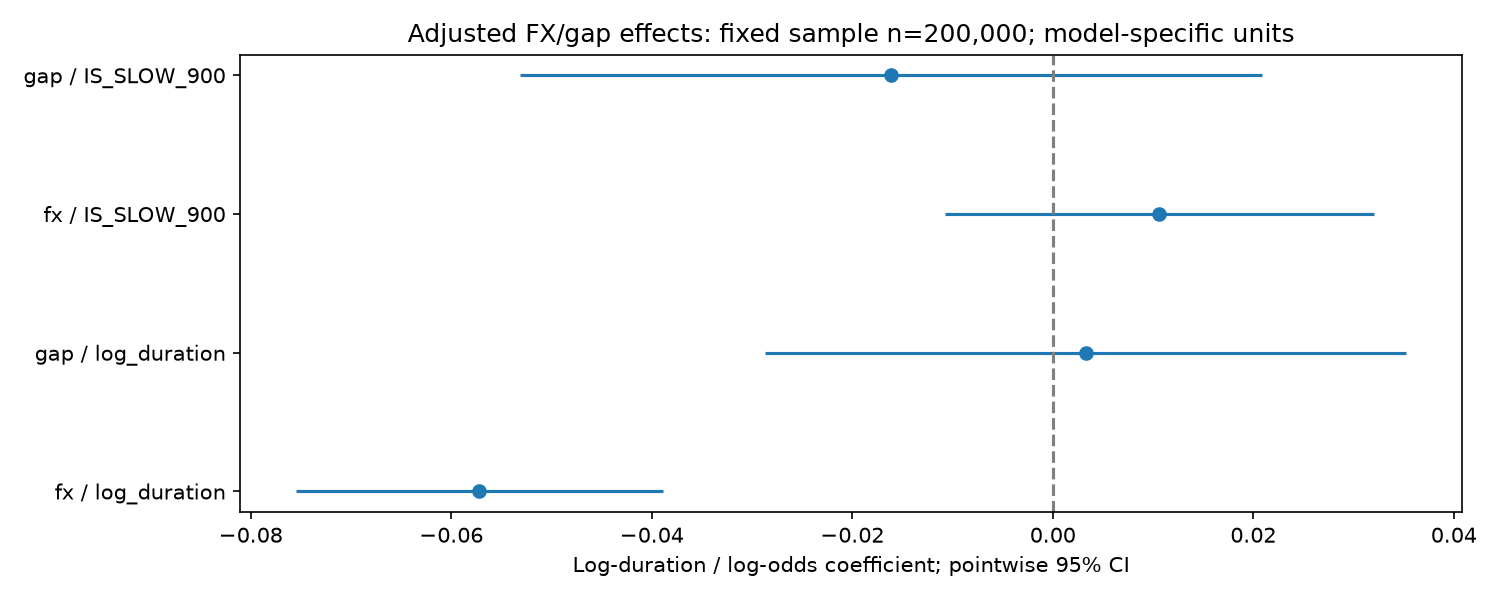

In [3]:
report = phase.finish(["Full-sample adjusted effects: " + effects.loc[effects.split.eq("full")].to_json(orient="records"), "Supported full matched comparisons: " + matching.loc[matching.split.eq("full")].to_json(orient="records")], ["Pointwise conditional uncertainty; no causal or external-validation claim.", "Restricted regression/common-support populations must not be generalized to the full network."])
display(Markdown("## Final findings and limitations\n" + "\n\n".join(report["findings"])))
display(Markdown("Generated tables: `" + str(phase.out.relative_to(ROOT)) + "`; charts: `" + str(phase.charts.relative_to(ROOT)) + "`. Source hashes and validation checks are in the completion manifest."))
for chart in sorted(phase.charts.glob("*.png")):
    display(Image(filename=str(chart)))
